# Models

In [6]:
import torch
import random

if torch.backends.mps.is_available():
    torch.set_default_device("mps")
    print("MPS device found!")


SEED = random.SystemRandom().randint(0, 2**32 - 1)
torch.manual_seed(SEED)
print(f"Random seed: {SEED}")

MPS device found!
Random seed: 2381672959


## Linear Regression (Raw)

Epoch 00: Loss=3.1100, W=0.706, b=1.006
Epoch 10: Loss=2.3498, W=0.975, b=0.987
Epoch 20: Loss=1.8782, W=1.188, b=0.974
Epoch 30: Loss=1.5853, W=1.355, b=0.966
Epoch 40: Loss=1.4035, W=1.487, b=0.961
Epoch 50: Loss=1.2905, W=1.592, b=0.958
Epoch 60: Loss=1.2202, W=1.674, b=0.957
Epoch 70: Loss=1.1765, W=1.739, b=0.957
Epoch 80: Loss=1.1493, W=1.790, b=0.957
Epoch 90: Loss=1.1323, W=1.830, b=0.958


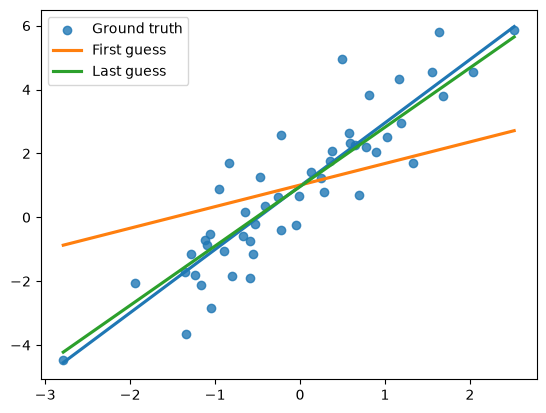

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from torch import Tensor
from numpy.typing import NDArray

def to_numpy(tensor: Tensor) -> NDArray:
    return tensor.detach().cpu().numpy().squeeze()

fig, ax = plt.subplots()

def add_to_plot(X: Tensor, Y: Tensor, label: str, isShowMarkers: bool = True):
    sns.regplot(
        x=to_numpy(X),
        y=to_numpy(Y),
        ax=ax,
        ci=None,
        scatter=isShowMarkers,
        label=label
    )

N = 50
D_x = 1
D_y = 1
X = torch.randn(N, D_x)

# True data generator
true_W = torch.tensor([[2.0]])
true_b = torch.tensor([[1]])
y_true = X @ true_W + true_b + 1.0*torch.randn(N, D_y)

# Model
W, b = torch.randn(D_x, D_y, requires_grad=True), torch.randn(1, D_y, requires_grad=True)
learning_rate, epochs = 0.01, 100

add_to_plot(X, y_true, "Ground truth")

# Forward pass
y_hat = X@W+b

add_to_plot(X, y_hat, "First guess", False)

for epoch in range(epochs):

    loss = torch.mean((y_hat - y_true) ** 2)

    # Backwards pass: compute gradients
    loss.backward()

    # Update params
    with torch.no_grad():
        W -= learning_rate * W.grad; b-= learning_rate * b.grad

    # Zero gradients
    W.grad.zero_(); b.grad.zero_()

    if epoch % 10 == 0:
        print(f"Epoch {epoch:02d}: Loss={loss.item():.4f}, W={W.item():.3f}, b={b.item():.3f}")

    # Forward pass
    y_hat = X@W+b



add_to_plot(X, y_hat, "Last guess", False)

ax.legend()
plt.show()